In [ ]:
# Paths are relative to the notebooks/ folder of this repository.
# On Google Colab, clone the repository first and run from notebooks/:
#   !git clone https://github.com/Syukrondzeko/natural-disaster-app-review-analysis.git
#   %cd natural-disaster-app-review-analysis/notebooks
DATA_DIR = "../data"

In [ ]:
import pandas as pd

input_path = f"{DATA_DIR}/3_clean/clean_df.xlsx"

df = pd.read_excel(input_path)


In [ ]:
df

,app,content,score,source,language,content_translated
0,disaster alert,"Working as a Public Health Nurse, I get to res...",5,play_store,English,"working as a public health nurse, i get to res..."
1,disaster alert,"Nice to have, before traveling to unknown terr...",5,play_store,English,"nice to have, before traveling to unknown terr..."
2,disaster alert,I like! I'm trying to find anything about tsun...,5,play_store,English,i like! i'm trying to find anything about tsun...
3,disaster alert,good to have but what options are expected in ...,5,play_store,English,good to have but what options are expected in ...
4,disaster alert,"Shows hazards, all right, but refuses to send ...",2,play_store,English,"shows hazards, all right, but refuses to send ..."
...,...,...,...,...,...,...
48616,bd 999,৯৯৯ এপপস এর apk লিংটা দেওয়া যাবে ভাইয়া আমি এক...,5,play_store,Bengali,i'll use the llpe link to your apps and increa...
48617,earthquakes near me,সাথে সাথে পাওয়া যায়না alert,2,play_store,Bengali,you can't get with me
48618,my earthquake alerts,সঠিক লোকেশন দেন না কেন,1,play_store,Bengali,why don't you give me the exact location?
48619,my earthquake alerts,"এটি একটি ভালো মাধ্যম, যার মাধ্যমে বিভিন্ন মানু...",3,play_store,Bengali,it is a good way to warn people about the eart...


In [ ]:
!pip install -q bertopic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 6.1 MB/s eta 0:00:00


# 1. Evaluation Metrics

## 1.1. Fitting Model

In [ ]:
import time
import os
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer

# ========================================
# Step 1: Compute embeddings ONCE
# ========================================
print("=== Step 1: Computing embeddings ===")

texts = df["content_translated"].astype(str).tolist()

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

start_time = time.time()
embeddings = embedding_model.encode(
    texts,
    show_progress_bar=True
)

import numpy as np

np.save(f"{DATA_DIR}/3_clean/embeddings.npy", embeddings)
print("[EMBEDDING] Embeddings saved to disk")

print(f"[EMBEDDING] Done in {time.time() - start_time:.2f} seconds")
print(f"[EMBEDDING] Shape: {embeddings.shape}")

# ========================================
# Step 2: Topic modeling function (reuse embeddings)
# ========================================
def run_topic_modeling(df, column, embeddings, nr_topics):
    print("\n======================================")
    print(f"[RUN START] nr_topics = {nr_topics}")
    print("======================================")

    print("[INIT] Initializing BERTopic model")
    topic_model = BERTopic(
        nr_topics=nr_topics,
        embedding_model=embedding_model,
        verbose=True
    )

    print("[FIT] Calling fit_transform")
    fit_start = time.time()

    topics, probabilities = topic_model.fit_transform(
        df[column].astype(str),
        embeddings
    )

    fit_end = time.time()
    print(f"[FIT] fit_transform finished in {fit_end - fit_start:.2f} seconds")

    print("[POST] Extracting topic info")
    post_start = time.time()
    topic_info = topic_model.get_topic_info()
    post_end = time.time()

    print(f"[POST] get_topic_info took {post_end - post_start:.2f} seconds")
    print(f"[POST] Topics found (including -1): {len(topic_info)}")

    print("[POST] Assigning clusters to dataframe")
    df_result = df.copy()
    df_result["cluster"] = topics
    df_result["topic_probability"] = probabilities

    print(f"[RUN END] nr_topics = {nr_topics}")
    return topic_info, df_result

# ========================================
# Step 3: Loop nr_topics from 20 to 35
# ========================================
BASE_OUT_DIR = f"{DATA_DIR}/4_topics/exp"
os.makedirs(BASE_OUT_DIR, exist_ok=True)

results = {}

total_loop_start = time.time()

for nr_topics in range(20, 36):
    loop_start = time.time()
    print("\n##################################################")
    print(f"[LOOP START] nr_topics = {nr_topics}")
    print("##################################################")

    topic_info, result_df = run_topic_modeling(
        df,
        "content_translated",
        embeddings,
        nr_topics
    )

    print("[SAVE] Saving topic_info to Excel")
    save_start = time.time()
    topic_info.to_excel(
        f"{BASE_OUT_DIR}/{nr_topics}_topic_info.xlsx",
        index=False
    )
    print(f"[SAVE] topic_info saved in {time.time() - save_start:.2f} seconds")

    print("[SAVE] Saving result_df to Excel")
    save_start = time.time()
    result_df.to_excel(
        f"{BASE_OUT_DIR}/{nr_topics}_result_df.xlsx",
        index=False
    )
    print(f"[SAVE] result_df saved in {time.time() - save_start:.2f} seconds")

    results[nr_topics] = {
        "topic_info": topic_info,
        "df": result_df
    }

    print(f"[LOOP END] nr_topics = {nr_topics} | Total time = {time.time() - loop_start:.2f} seconds")

total_loop_end = time.time()
print("\n======================================")
print(f"[ALL DONE] Total loop time: {total_loop_end - total_loop_start:.2f} seconds")
print("======================================")


/usr/local/lib/python3.12/dist-packages/hdbscan/robust_single_linkage_.py:175: SyntaxWarning: invalid escape sequence '\{'
  $max \{ core_k(a), core_k(b), 1/\alpha d(a,b) \}$.


=== Step 1: Computing embeddings ===


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (68 outputs left out)

2026-01-05 04:52:12,942 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm


[SAVE] result_df saved in 6.43 seconds
[LOOP END] nr_topics = 34 | Total time = 57.77 seconds

##################################################
[LOOP START] nr_topics = 35
##################################################

[RUN START] nr_topics = 35
[INIT] Initializing BERTopic model
[FIT] Calling fit_transform


2026-01-05 04:52:58,748 - BERTopic - Dimensionality - Completed ✓
2026-01-05 04:52:58,751 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-01-05 04:53:02,182 - BERTopic - Cluster - Completed ✓
2026-01-05 04:53:02,183 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-01-05 04:53:03,109 - BERTopic - Representation - Completed ✓
2026-01-05 04:53:03,110 - BERTopic - Topic reduction - Reducing number of topics
2026-01-05 04:53:03,189 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-01-05 04:53:03,935 - BERTopic - Representation - Completed ✓
2026-01-05 04:53:03,942 - BERTopic - Topic reduction - Reduced number of topics from 424 to 35


[FIT] fit_transform finished in 51.16 seconds
[POST] Extracting topic info
[POST] get_topic_info took 0.00 seconds
[POST] Topics found (including -1): 35
[POST] Assigning clusters to dataframe
[RUN END] nr_topics = 35
[SAVE] Saving topic_info to Excel
[SAVE] topic_info saved in 0.02 seconds
[SAVE] Saving result_df to Excel
[SAVE] result_df saved in 6.44 seconds
[LOOP END] nr_topics = 35 | Total time = 57.69 seconds

[ALL DONE] Total loop time: 946.07 seconds


## 1.2. Metrics for All Number of Clusters

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.metrics import pairwise_distances
import matplotlib.pyplot as plt

# ========================================
# Step 1: Load embeddings
# ========================================
embeddings = np.load(f"{DATA_DIR}/3_clean/embeddings.npy")
print(f"[INFO] Loaded embeddings: {embeddings.shape}")

# ========================================
# Step 2: Loop over all nr_topics files
# ========================================
BASE_DIR = f"{DATA_DIR}/4_topics/exp"
nr_topics_range = range(20, 36)

db_scores = {}
sil_scores = {}
wss_scores = {}
mean_probs = {}
median_probs = {}

for nr_topics in nr_topics_range:
    print(f"\n[LOOP] Processing nr_topics = {nr_topics}")

    # Load the result dataframe
    df_path = f"{BASE_DIR}/{nr_topics}_result_df.xlsx"
    df = pd.read_excel(df_path)

    # Filter out cluster = -1
    mask = df['cluster'] != -1
    filtered_embeddings = embeddings[mask.values]
    filtered_clusters = df.loc[mask, 'cluster'].values

    # Skip if not enough clusters
    unique_clusters = np.unique(filtered_clusters)
    if len(unique_clusters) < 2:
        print("[WARNING] Less than 2 clusters after filtering, skipping metrics")
        db_scores[nr_topics] = np.nan
        sil_scores[nr_topics] = np.nan
        wss_scores[nr_topics] = np.nan
        mean_probs[nr_topics] = np.nan
        median_probs[nr_topics] = np.nan
        continue

    # 1️⃣ Davies-Bouldin Score
    db_scores[nr_topics] = davies_bouldin_score(filtered_embeddings, filtered_clusters)

    # 2️⃣ Silhouette Score
    sil_scores[nr_topics] = silhouette_score(filtered_embeddings, filtered_clusters)

    # 3️⃣ WSS (Within-cluster sum of squares)
    wss = 0.0
    for cluster_id in unique_clusters:
        cluster_points = filtered_embeddings[filtered_clusters == cluster_id]
        centroid = cluster_points.mean(axis=0)
        wss += np.sum(np.linalg.norm(cluster_points - centroid, axis=1)**2)
    wss_scores[nr_topics] = wss

    # 4️⃣ Mean and Median of topic_probability
    topic_probs = df.loc[mask, 'topic_probability'].apply(
        lambda x: np.array(eval(x)) if isinstance(x, str) else np.array(x)
    )
    doc_mean_probs = topic_probs.apply(np.mean)
    doc_median_probs = topic_probs.apply(np.median)
    mean_probs[nr_topics] = doc_mean_probs.mean()
    median_probs[nr_topics] = doc_median_probs.median()

# ========================================
# Step 3: Convert results to DataFrame
# ========================================
metrics_df = pd.DataFrame({
    "nr_topics": list(nr_topics_range),
    "davies_bouldin": [db_scores[n] for n in nr_topics_range],
    "silhouette": [sil_scores[n] for n in nr_topics_range],
    "wss": [wss_scores[n] for n in nr_topics_range],
    "mean_prob": [mean_probs[n] for n in nr_topics_range],
    "median_prob": [median_probs[n] for n in nr_topics_range]
})

print("\n[SUMMARY]")
print(metrics_df)

# Save summary
metrics_df.to_excel(f"{BASE_DIR}/metrics_summary.xlsx", index=False)
print(f"[INFO] Saved summary to {BASE_DIR}/metrics_summary.xlsx")



[INFO] Loaded embeddings: (48621, 384)

[LOOP] Processing nr_topics = 20

[LOOP] Processing nr_topics = 21

[LOOP] Processing nr_topics = 22

[LOOP] Processing nr_topics = 23

[LOOP] Processing nr_topics = 24

[LOOP] Processing nr_topics = 25

[LOOP] Processing nr_topics = 26

[LOOP] Processing nr_topics = 27

[LOOP] Processing nr_topics = 28

[LOOP] Processing nr_topics = 29

[LOOP] Processing nr_topics = 30

[LOOP] Processing nr_topics = 31

[LOOP] Processing nr_topics = 32

[LOOP] Processing nr_topics = 33

[LOOP] Processing nr_topics = 34

[LOOP] Processing nr_topics = 35

[SUMMARY]
    nr_topics  davies_bouldin  silhouette           wss  mean_prob  \
0          20        3.293783    0.025069  21965.824219   0.802168   
1          21        3.443783    0.020775  21079.486328   0.803090   
2          22        3.283745    0.030912  24564.964844   0.853294   
3          23        3.167809    0.023209  20277.931641   0.778161   
4          24        3.078945    0.014283  20535.341797 

## 1.3. Number of Cluster Comparison

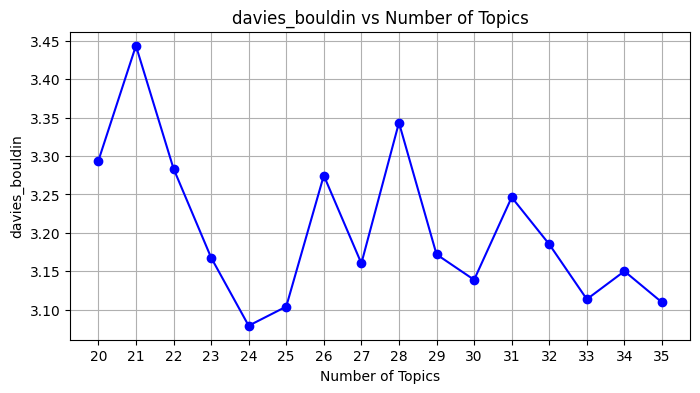

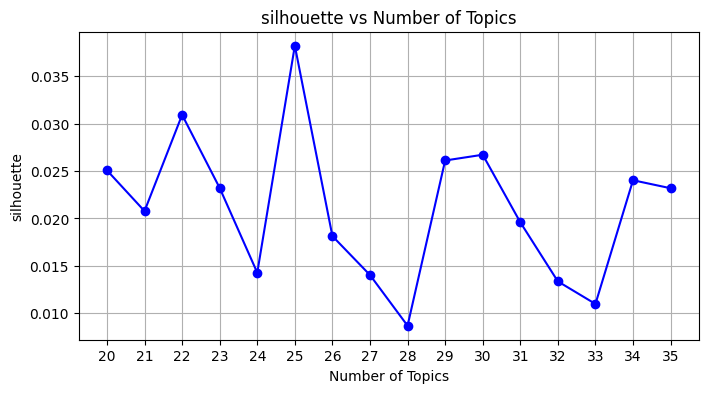

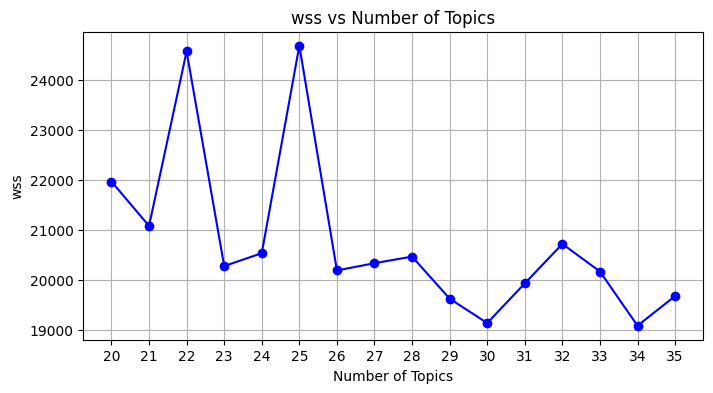

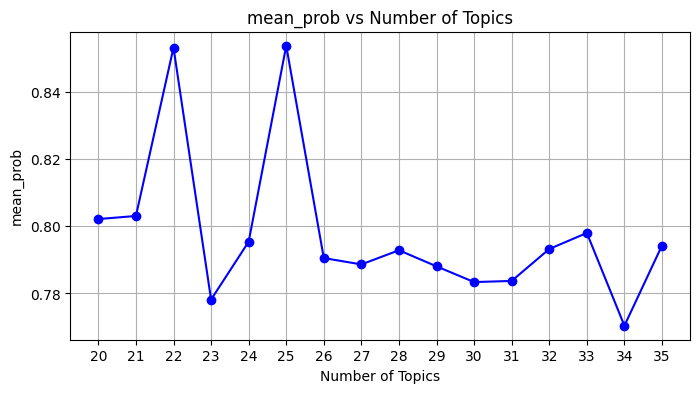

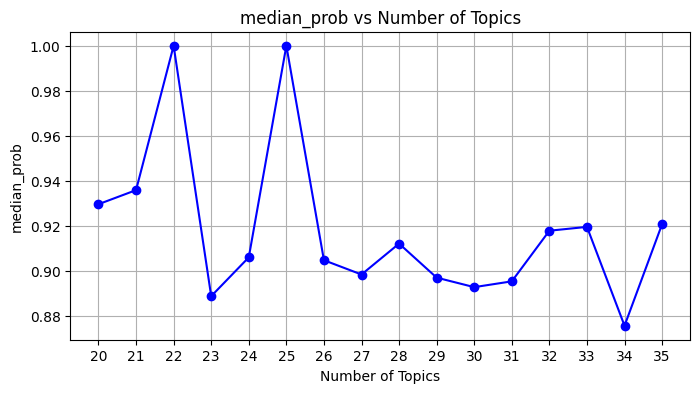

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df_path = f"{DATA_DIR}/4_topics/exp/metrics_summary.xlsx"
df = pd.read_excel(df_path)

# Metrics to plot
metrics = ['davies_bouldin', 'silhouette', 'wss', 'mean_prob', 'median_prob']

# Create a plot for each metric
for metric in metrics:
    plt.figure(figsize=(8, 4))
    plt.plot(df['nr_topics'], df[metric], marker='o', linestyle='-', color='b')
    plt.title(f'{metric} vs Number of Topics')
    plt.xlabel('Number of Topics')
    plt.ylabel(metric)
    plt.grid(True)
    plt.xticks(df['nr_topics'])  # show all topic numbers
    plt.show()


Metric Interpretation

Here is an overview of the metrics and whether higher or lower values are better:

| Metric                | Better?      | Description |
|----------------------|-------------|-------------|
| **Davies-Bouldin**    | Lower       | Measures cluster separation. Smaller values mean clusters are more distinct and compact. |
| **Silhouette**        | Higher      | Measures how similar a point is to its own cluster vs other clusters. Closer to 1 is ideal. |
| **WSS (Within-Cluster Sum of Squares)** | Lower       | Measures cluster compactness. Smaller values indicate tighter clusters. |
| **Mean Probability**  | Higher      | Average confidence of topic assignments in BERTopic. Higher is better. |
| **Median Probability**| Higher      | Median confidence of topic assignments. Less sensitive to outliers than the mean. |


# 2. Refining Clusters

In [ ]:
BASE_DIR = f"{DATA_DIR}/4_topics/exp"
nr_topics = 25

topic_info_path = f"{BASE_DIR}/{nr_topics}_topic_info.xlsx"
topic_info = pd.read_excel(topic_info_path)

df_path = f"{BASE_DIR}/{nr_topics}_result_df.xlsx"
df = pd.read_excel(df_path)
df['id'] = range(len(df))

1. Alert Functionality
2. Map Usage
3. Monetary Transaction
4. Location Functionality
5. Disaster Updates
6. App Crashes
7. Alert Sound
8. Slow Performance
9. Bug Fixes
10. App Configuration
11. User Interface
12. User Safety
13. Sign In and Sign Up Problem
14. Network Connectivity
15. Watch Zone Functionality
16. Batteray Drainage
17. Reliability
18. Language Preferences

In [ ]:
topic_info

,Topic,Count,Name,Representation,Representative_Docs
0,-1,13957,-1_it_the_to_and,"['it', 'the', 'to', 'and', 'app', 'is', 'this'...",['i love this app. i am an insurance adjuster ...
1,0,28824,0_the_app_to_it,"['the', 'app', 'to', 'it', 'and', 'this', 'is'...",['greetings ~ i waited awhile before placing a...
2,1,2690,1_very_accurate_easy_and,"['very', 'accurate', 'easy', 'and', 'to', 'inf...","['very easy to use; fast and accurate.', 'very..."
3,2,605,2_language_english_in_rico,"['language', 'english', 'in', 'rico', 'puerto'...","['app is useful, although i use english as pri..."
4,3,473,3_world_what_earth_going,"['world', 'what', 'earth', 'going', 'safe', 'k...","[""i like to know what's happening around the w..."
5,4,410,4_good_so_far_best,"['good', 'so', 'far', 'best', 'it', 'very', 'l...","['so far so good i like this very much.', 'ver..."
6,5,351,5_works_does_it_working,"['works', 'does', 'it', 'working', 'says', 'wh...","['does what it says', 'does exactly what it sa..."
7,6,157,6_thank_you_keep_work,"['thank', 'you', 'keep', 'work', 'job', 'good'...",['you have done a good job. thank you so much'...
8,7,136,7_california_alaska_in_living,"['california', 'alaska', 'in', 'living', 'live...",['easy to use and i live on the coast in alask...
9,8,132,8_magnitude_miles_distance_km,"['magnitude', 'miles', 'distance', 'km', 'kilo...","[""sensitivity is not very good. i have anothe..."


In [ ]:
# import os

# # Define the output directory
# output_dir = f"{DATA_DIR}/4_topics/temp"
# os.makedirs(output_dir, exist_ok=True)  # Make sure the folder exists

# # Export cluster_0_df
# cluster_0_df_path = os.path.join(output_dir, "cluster_0_df.xlsx")
# cluster_0_df.to_excel(cluster_0_df_path, index=False)

# # Export cluster_0_topic_info
# cluster_0_topic_info_path = os.path.join(output_dir, "cluster_0_topic_info.xlsx")
# cluster_0_topic_info.to_excel(cluster_0_topic_info_path, index=False)

# print("Export completed successfully!")


Export completed successfully!


In [ ]:
BASE_DIR = f"{DATA_DIR}/4_topics/refining"

## 2.1. Cluster 0

In [ ]:
from bertopic import BERTopic
import pandas as pd
import time

# Filter reviews belonging to cluster 0
cluster_0_df = df[df['cluster'] == 0].copy()
texts = cluster_0_df['content_translated'].tolist()  # replace 'text' with your actual text column name

# Parameters for refining
min_topic_size = 5  # smaller because we're focusing on a subset
nr_topics = None    # let BERTopic find the optimal number of topics automatically

# Initialize BERTopic
topic_model = BERTopic(
    min_topic_size=min_topic_size,
    nr_topics=nr_topics,
    embedding_model="all-MiniLM-L6-v2",
    verbose=True
)

# Fit the model on cluster 0 texts
start_time = time.time()
topics, probs = topic_model.fit_transform(texts)
end_time = time.time()

print(f"Refined BERTopic done in {end_time - start_time:.2f} seconds")

# Add the new refined topics to the dataframe
cluster_0_df['refined_topic'] = topics

# View topic info
cluster_0_topic_info = topic_model.get_topic_info()

2026-01-05 05:49:54,241 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/901 [00:00<?, ?it/s]

2026-01-05 05:50:11,287 - BERTopic - Embedding - Completed ✓
2026-01-05 05:50:11,289 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-01-05 05:50:36,541 - BERTopic - Dimensionality - Completed ✓
2026-01-05 05:50:36,543 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-01-05 05:50:41,788 - BERTopic - Cluster - Completed ✓
2026-01-05 05:50:41,799 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-01-05 05:50:42,527 - BERTopic - Representation - Completed ✓


Refined BERTopic done in 49.46 seconds


In [ ]:
cluster_0_topic_info

,Topic,Count,Name,Representation,Representative_Docs
0,-1,7612,-1_earthquake_earthquakes_quake_quakes,"[earthquake, earthquakes, quake, quakes, an, i...",[this app never works for me and never sends a...
1,0,2475,0_fire_fires_watch_zone,"[fire, fires, watch, zone, zones, nsw, ready, ...","[no fires : (, the app won't let me scroll so ..."
2,1,564,1_alarm_earthquake_notice_seconds,"[alarm, earthquake, notice, seconds, minutes, ...","[it's alert after earthquake not before, you c..."
3,2,472,2_alerts_alert_alerter_getting,"[alerts, alert, alerter, getting, same, app, b...","[alerts only when app is in use., good app for..."
4,3,455,3_hurricane_hurricanes_tracking_season,"[hurricane, hurricanes, tracking, season, flor...",[love it.. best app around for hurricane track...
...,...,...,...,...,...
460,459,5,459_grand_spotted_boats_measures,"[grand, spotted, boats, measures, planes, zoom...",[love the map it feature. let's me know how cl...
461,460,5,460_bothersome_uninstall_wait_uninstalled,"[bothersome, uninstall, wait, uninstalled, sor...","[i'm very sorry, but i couldn't receive notice..."
462,461,5,461_bcs_customize_especialy_awakening,"[bcs, customize, especialy, awakening, seas, o...",[not helpful at all. can't customize alerts. n...
463,462,5,462_waves_didnt_ratings_lorenzo,"[waves, didnt, ratings, lorenzo, abit, anyanag...",[it is a good app and works well its just the ...


### 2.1.1. Sub-Cluster 0

In [ ]:
from bertopic import BERTopic
import pandas as pd
import time

# Filter reviews belonging to cluster 0, subcluster 0
cluster_0_subcluster_0_df = cluster_0_df[cluster_0_df['refined_topic'] == 0].copy()
texts = cluster_0_subcluster_0_df['content_translated'].tolist()  # use the subcluster df

# Parameters for refining
min_topic_size = 5  # smaller because we're focusing on a subset
nr_topics = None    # let BERTopic find the optimal number of topics automatically

# Initialize BERTopic
topic_model = BERTopic(
    min_topic_size=min_topic_size,
    nr_topics=nr_topics,
    embedding_model="all-MiniLM-L6-v2",
    verbose=True
)

# Fit the model on the subcluster texts
start_time = time.time()
subtopics, subprobs = topic_model.fit_transform(texts)
end_time = time.time()

print(f"Refined BERTopic for cluster 0 subcluster 0 done in {end_time - start_time:.2f} seconds")

# Add the subcluster topics to the dataframe
cluster_0_subcluster_0_df['subcluster_topic'] = subtopics

# View topic info for this subcluster
cluster_0_subcluster_0_topic_info = topic_model.get_topic_info()
print(cluster_0_subcluster_0_topic_info)


2026-01-05 05:50:43,766 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/78 [00:00<?, ?it/s]

2026-01-05 05:50:47,435 - BERTopic - Embedding - Completed ✓
2026-01-05 05:50:47,437 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-01-05 05:50:57,903 - BERTopic - Dimensionality - Completed ✓
2026-01-05 05:50:57,904 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-01-05 05:50:57,984 - BERTopic - Cluster - Completed ✓
2026-01-05 05:50:57,989 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-01-05 05:50:58,113 - BERTopic - Representation - Completed ✓


Refined BERTopic for cluster 0 subcluster 0 done in 14.56 seconds
    Topic  Count                                     Name  \
0      -1   1167                       -1_the_and_to_fire   
1       0     49                    0_watch_zone_save_won   
2       1     48           1_profile_create_account_watch   
3       2     43            2_great_during_bush_excellent   
4       3     38  3_zone_notification_notifications_watch   
..    ...    ...                                      ...   
86     85      5          85_password_email_logging_reset   
87     86      5                    86_distance_as_you_if   
88     87      5   87_incidents_including_immediate_event   
89     88      5       88_instantly_threat_oceans_surface   
90     89      5         89_notification_smoke_them_nerds   

                                       Representation  \
0     [the, and, to, fire, app, it, in, is, of, this]   
1   [watch, zone, save, won, zones, let, create, s...   
2   [profile, create, account,

#### 2.1.1.1. Sub-Sub-Cluster 0

Result: Watch Zone Functionality

- Watch Zone Problems
- Watch Zone Setup Issues
- Difficulties Managing Watch Zones

In [ ]:
# exporting_df = cluster_0_subcluster_0_df[cluster_0_subcluster_0_df.subcluster_topic == 0].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_0_df.xlsx",
#     index=False
# )

#### 2.1.1.2 Sub-Sub-Cluster 1

Result: Watch Zone Functionality

- Forced Profile Creation
- Watch Zones Blocked by Profile Requirement
- Account Issues Preventing Watch Zones

In [ ]:
# exporting_df = cluster_0_subcluster_0_df[cluster_0_subcluster_0_df.subcluster_topic == 1].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_1_df.xlsx",
#     index=False
# )

#### 2.1.1.3 Sub-Sub-Cluster 3

Result: Alert Functionality

- Alert Overload and Missed Notifications
- Notification Reliability Problems
- Watch Zone Alerts Dysfunction

In [ ]:
# exporting_df = cluster_0_subcluster_0_df[cluster_0_subcluster_0_df.subcluster_topic == 3].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_3_df.xlsx",
#     index=False
# )

#### 2.1.1.4 Sub-Sub-Cluster 4

Result: Alert Functionality

- Late or Missed Notifications
- Unreliable Fire Alerts
- Notification Timeliness Problems

In [ ]:
# exporting_df = cluster_0_subcluster_0_df[cluster_0_subcluster_0_df.subcluster_topic == 4].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_4_df.xlsx",
#     index=False
# )

#### 2.1.1.5 Sub-Sub-Cluster 5

Result: Reliability

- Missing or Delayed Fire Data
- Fire Status Confusion
- Insufficient Incident Information

In [ ]:
# exporting_df = cluster_0_subcluster_0_df[cluster_0_subcluster_0_df.subcluster_topic == 5].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_5_df.xlsx",
#     index=False
# )

#### 2.1.1.6 Sub-Sub-Cluster 6

Result: Geographical Coverage

- State-Limited App Complaints
- Navigation and Coverage Issues
- Need for National Fire App

In [ ]:
# exporting_df = cluster_0_subcluster_0_df[cluster_0_subcluster_0_df.subcluster_topic == 6].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_6_df.xlsx",
#     index=False
# )

#### 2.1.1.7 Sub-Sub-Cluster 9

Result: Watch Zone Functionality

- Watch Zone Functionality
- Positive Feedback on Watch Zones
- Watch Zone Improvements

In [ ]:
# exporting_df = cluster_0_subcluster_0_df[cluster_0_subcluster_0_df.subcluster_topic == 9].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_9_df.xlsx",
#     index=False
# )

#### 2.1.1.8 Sub-Sub-Cluster 10

Result: App Updates

- Fire Ready vs New App Comparison
- Negative Feedback on New App Update
- Old App Superior, New App Frustrating

In [ ]:
# exporting_df = cluster_0_subcluster_0_df[cluster_0_subcluster_0_df.subcluster_topic == 10].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_10_df.xlsx",
#     index=False
# )

In [ ]:
cluster_idx = 10
print(len(cluster_0_subcluster_0_df[cluster_0_subcluster_0_df.subcluster_topic == cluster_idx]))

24


### 2.1.2. Sub-Cluster 1

Result: Alert Functionality

- Earthquake Notifications: Delays, Missed Alerts, and False Alarms
- Timely Earthquake Alerts and User Frustrations
- Earthquake Warning System Feedback

In [ ]:
cluster_0_subcluster_1_df = cluster_0_df[cluster_0_df['refined_topic'] == 1].copy()


In [ ]:
# exporting_df = cluster_0_subcluster_1_df[cluster_0_subcluster_1_df.refined_topic == 1].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_1_df.xlsx",
#     index=False
# )

### 2.1.3. Sub-Cluster 2

Result: Alert Functionality

- Missing alerts, delayed alerts, empty notifications
- Duplicate/redundant notifications
- Difficult to uninstall or configure alerts

In [ ]:
from bertopic import BERTopic
import pandas as pd
import time

# Filter reviews belonging to cluster 0, subcluster 0
cluster_0_subcluster_2_df = cluster_0_df[cluster_0_df['refined_topic'] == 2].copy()
texts = cluster_0_subcluster_2_df['content_translated'].tolist()  # use the subcluster df

# Parameters for refining
min_topic_size = 5  # smaller because we're focusing on a subset
nr_topics = None    # let BERTopic find the optimal number of topics automatically

# Initialize BERTopic
topic_model = BERTopic(
    min_topic_size=min_topic_size,
    nr_topics=nr_topics,
    embedding_model="all-MiniLM-L6-v2",
    verbose=True
)

# Fit the model on the subcluster texts
start_time = time.time()
subtopics, subprobs = topic_model.fit_transform(texts)
end_time = time.time()

print(f"Refined BERTopic for cluster 0 subcluster 0 done in {end_time - start_time:.2f} seconds")

# Add the subcluster topics to the dataframe
cluster_0_subcluster_2_df['subcluster_topic'] = subtopics

# View topic info for this subcluster
cluster_0_subcluster_2_topic_info = topic_model.get_topic_info()
print(cluster_0_subcluster_2_topic_info)


2026-01-05 06:33:00,947 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/15 [00:00<?, ?it/s]

2026-01-05 06:33:03,730 - BERTopic - Embedding - Completed ✓
2026-01-05 06:33:03,731 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-01-05 06:33:04,590 - BERTopic - Dimensionality - Completed ✓
2026-01-05 06:33:04,591 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-01-05 06:33:04,608 - BERTopic - Cluster - Completed ✓
2026-01-05 06:33:04,612 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-01-05 06:33:04,634 - BERTopic - Representation - Completed ✓


Refined BERTopic for cluster 0 subcluster 0 done in 3.72 seconds
    Topic  Count                            Name  \
0      -1    162                -1_the_app_to_it   
1       0    129         0_app_alerts_good_great   
2       1     30           1_the_minutes_same_it   
3       2     26                 2_to_it_the_and   
4       3     25    3_notifications_the_there_no   
5       4     19        4_off_app_uninstalled_to   
6       5     18  5_for_subscription_alerts_that   
7       6     15            6_text_phone_the_app   
8       7     10          7_informed_you_it_that   
9       8      9     8_quicker_jake_faster_alert   
10      9      8      9_getting_awhile_not_doesn   
11     10      7         10_thats_bought_usgs_it   
12     11      7    11_me_date_immediate_updated   
13     12      7            12_open_but_all_them   

                                       Representation  \
0   [the, app, to, it, alerts, this, and, is, aler...   
1   [app, alerts, good, great, alert, to

In [ ]:
cluster_0_subcluster_2_df = cluster_0_df[cluster_0_df['refined_topic'] == 2].copy()


In [ ]:
# exporting_df = cluster_0_subcluster_2_df[cluster_0_subcluster_2_df.refined_topic == 2].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_2_df.xlsx",
#     index=False
# )

### 2.1.4. Sub-Cluster 3

Result: Keep Updated

- Reviews focusing on keeping up with current storms and accuracy.

In [ ]:
from bertopic import BERTopic
import pandas as pd
import time

# Filter reviews belonging to cluster 0, subcluster 0
cluster_0_subcluster_3_df = cluster_0_df[cluster_0_df['refined_topic'] == 3].copy()
texts = cluster_0_subcluster_3_df['content_translated'].tolist()  # use the subcluster df

# Parameters for refining
min_topic_size = 5  # smaller because we're focusing on a subset
nr_topics = None    # let BERTopic find the optimal number of topics automatically

# Initialize BERTopic
topic_model = BERTopic(
    min_topic_size=min_topic_size,
    nr_topics=nr_topics,
    embedding_model="all-MiniLM-L6-v2",
    verbose=True
)

# Fit the model on the subcluster texts
start_time = time.time()
subtopics, subprobs = topic_model.fit_transform(texts)
end_time = time.time()

print(f"Refined BERTopic for cluster 0 subcluster 0 done in {end_time - start_time:.2f} seconds")

# Add the subcluster topics to the dataframe
cluster_0_subcluster_3_df['subcluster_topic'] = subtopics

# View topic info for this subcluster
cluster_0_subcluster_3_topic_info = topic_model.get_topic_info()
print(cluster_0_subcluster_3_topic_info)


2026-01-05 06:39:04,144 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/15 [00:00<?, ?it/s]

2026-01-05 06:39:06,129 - BERTopic - Embedding - Completed ✓
2026-01-05 06:39:06,130 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-01-05 06:39:07,026 - BERTopic - Dimensionality - Completed ✓
2026-01-05 06:39:07,027 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-01-05 06:39:07,042 - BERTopic - Cluster - Completed ✓
2026-01-05 06:39:07,046 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-01-05 06:39:07,069 - BERTopic - Representation - Completed ✓


Refined BERTopic for cluster 0 subcluster 0 done in 2.97 seconds
    Topic  Count                                 Name  \
0      -1    160                   -1_the_to_app_this   
1       0     43    0_tracking_hurricane_tracker_best   
2       1     36               1_it_season_app_during   
3       2     35             2_best_hurricane_the_app   
4       3     35               3_live_florida_in_this   
5       4     26            4_tropical_storms_the_and   
6       5     18                   5_track_app_it_and   
7       6     18             6_info_to_easy_hurricane   
8       7     15         7_hurricanes_tracking_to_app   
9       8     11        8_cyclone_cyclones_very_track   
10      9     11                9_accurate_it_of_this   
11     10     11               10_working_not_now_was   
12     11     10          11_hurricanes_phone_app_for   
13     12      7     12_information_tracking_one_good   
14     13      7         13_best_information_all_here   
15     14      7  14_tr

In [ ]:
cluster_0_subcluster_3_df = cluster_0_df[cluster_0_df['refined_topic'] == 3]

In [ ]:
# exporting_df = cluster_0_subcluster_3_df[cluster_0_subcluster_3_df.refined_topic == 3].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_3_df.xlsx",
#     index=False
# )

### 2.1.5. Sub-Cluster 4

Result: Payment Scheme

- Intrusive / Excessive Ads (Negative Reviews)
- Ad-Free or Minimal Ads (Positive Reviews)
- Mixed / Paid Version Feedback

In [ ]:
cluster_0_subcluster_4_df = cluster_0_df[cluster_0_df['refined_topic'] == 4]

In [ ]:
# exporting_df = cluster_0_subcluster_4_df[cluster_0_subcluster_4_df.refined_topic == 4].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_4_df.xlsx",
#     index=False
# )

### 2.1.6. Sub-Cluster 5

Result: Payment Scheme

- Intrusive / Excessive Ads (Negative Reviews)
- Ad-Free or Minimal Ads (Positive Reviews)
- Mixed / Paid Version Feedback

In [ ]:
from bertopic import BERTopic
import pandas as pd
import time

# Filter reviews belonging to cluster 0, subcluster 0
cluster_0_subcluster_5_df = cluster_0_df[cluster_0_df['refined_topic'] == 5].copy()
texts = cluster_0_subcluster_5_df['content_translated'].tolist()  # use the subcluster df

# Parameters for refining
min_topic_size = 5  # smaller because we're focusing on a subset
nr_topics = None    # let BERTopic find the optimal number of topics automatically

# Initialize BERTopic
topic_model = BERTopic(
    min_topic_size=min_topic_size,
    nr_topics=nr_topics,
    embedding_model="all-MiniLM-L6-v2",
    verbose=True
)

# Fit the model on the subcluster texts
start_time = time.time()
subtopics, subprobs = topic_model.fit_transform(texts)
end_time = time.time()

print(f"Refined BERTopic for cluster 0 subcluster 0 done in {end_time - start_time:.2f} seconds")

# Add the subcluster topics to the dataframe
cluster_0_subcluster_5_df['subcluster_topic'] = subtopics

# View topic info for this subcluster
cluster_0_subcluster_5_topic_info = topic_model.get_topic_info()
print(cluster_0_subcluster_5_topic_info)


2026-01-05 06:51:28,568 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/13 [00:00<?, ?it/s]

2026-01-05 06:51:30,399 - BERTopic - Embedding - Completed ✓
2026-01-05 06:51:30,401 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-01-05 06:51:31,133 - BERTopic - Dimensionality - Completed ✓
2026-01-05 06:51:31,134 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-01-05 06:51:31,149 - BERTopic - Cluster - Completed ✓
2026-01-05 06:51:31,151 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-01-05 06:51:31,175 - BERTopic - Representation - Completed ✓


Refined BERTopic for cluster 0 subcluster 0 done in 2.65 seconds
    Topic  Count                                  Name  \
0      -1    172                 -1_weather_the_to_app   
1       0     66               0_alerts_to_weather_app   
2       1     26                1_best_weather_one_app   
3       2     21            2_accurate_is_the_accuracy   
4       3     17                      3_this_the_it_on   
5       4     15                 4_is_weather_app_like   
6       5     12                5_was_know_for_weather   
7       6     10                  6_widget_for_they_it   
8       7     10                7_weather_app_love_you   
9       8     10                     8_isn_okay_it_app   
10      9      9                     9_and_live_the_in   
11     10      9     10_forecasts_forecast_for_weather   
12     11      7  11_events_awareness_aspects_emerging   
13     12      7           12_bad_safety_great_outdoor   
14     13      6              13_severe_for_have_learn   
15     

#### 2.1.6.1 Sub-Sub-Cluster 0

Result: Alert Functionality

- Severe Weather Alerts & Early Warnings
- Customization of Alerts

In [ ]:
# exporting_df = cluster_0_subcluster_5_df[cluster_0_subcluster_5_df.subcluster_topic == 0].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_5_subsubcluster_0_df.xlsx",
#     index=False
# )

#### 2.1.6.1 Sub-Sub-Cluster 2

Result: Reliability

- Accuracy of Weather Data
- Reliability / Trustworthiness

In [ ]:
# exporting_df = cluster_0_subcluster_5_df[cluster_0_subcluster_5_df.subcluster_topic == 2].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_5_subsubcluster_2_df.xlsx",
#     index=False
# )

#### 2.1.6.1 Sub-Sub-Cluster 3

Result: Reliability

- Reliability / Trustworthiness

In [ ]:
# exporting_df = cluster_0_subcluster_5_df[cluster_0_subcluster_5_df.subcluster_topic == 3].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_5_subsubcluster_3_df.xlsx",
#     index=False
# )

### 2.1.7. Sub-Cluster 6

Result: None

In [ ]:
from bertopic import BERTopic
import pandas as pd
import time

# Filter reviews belonging to cluster 0, subcluster 0
cluster_0_subcluster_6_df = cluster_0_df[cluster_0_df['refined_topic'] == 6].copy()
texts = cluster_0_subcluster_6_df['content_translated'].tolist()  # use the subcluster df

# Parameters for refining
min_topic_size = 5  # smaller because we're focusing on a subset
nr_topics = None    # let BERTopic find the optimal number of topics automatically

# Initialize BERTopic
topic_model = BERTopic(
    min_topic_size=min_topic_size,
    nr_topics=nr_topics,
    embedding_model="all-MiniLM-L6-v2",
    verbose=True
)

# Fit the model on the subcluster texts
start_time = time.time()
subtopics, subprobs = topic_model.fit_transform(texts)
end_time = time.time()

print(f"Refined BERTopic for cluster 0 subcluster 0 done in {end_time - start_time:.2f} seconds")

# Add the subcluster topics to the dataframe
cluster_0_subcluster_6_df['subcluster_topic'] = subtopics

# View topic info for this subcluster
cluster_0_subcluster_6_topic_info = topic_model.get_topic_info()
print(cluster_0_subcluster_6_topic_info)


2026-01-05 07:12:25,124 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/13 [00:00<?, ?it/s]

2026-01-05 07:12:26,925 - BERTopic - Embedding - Completed ✓
2026-01-05 07:12:26,927 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-01-05 07:12:27,618 - BERTopic - Dimensionality - Completed ✓
2026-01-05 07:12:27,619 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-01-05 07:12:27,634 - BERTopic - Cluster - Completed ✓
2026-01-05 07:12:27,638 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-01-05 07:12:27,657 - BERTopic - Representation - Completed ✓


Refined BERTopic for cluster 0 subcluster 0 done in 2.56 seconds
   Topic  Count                       Name  \
0     -1    149           -1_the_app_to_in   
1      0    135            0_app_to_the_it   
2      1     31      1_best_quake_app_this   
3      2     20           2_in_we_live_and   
4      3     12    3_the_around_that_world   
5      4     11     4_world_quakes_see_all   
6      5     11  5_shows_where_info_quakes   
7      6     11    6_earth_quake_good_have   
8      7     10     7_earth_this_there_app   
9      8      5       8_how_many_day_there   

                                      Representation  \
0  [the, app, to, in, this, quakes, of, quake, is...   
1  [app, to, the, it, and, this, quakes, quake, g...   
2  [best, quake, app, this, out, ve, my, it, is, ...   
3  [in, we, live, and, have, this, the, quakes, a...   
4  [the, around, that, world, quakes, and, know, ...   
5  [world, quakes, see, all, app, wide, very, can...   
6  [shows, where, info, quakes, app,

### 2.1.8. Sub-Cluster 7

Result: Location Functionality

- Location Detection Failures
- Manual Location Entry Issues
- Multiple Locations / Home Location Problems

In [ ]:
from bertopic import BERTopic
import pandas as pd
import time

# Filter reviews belonging to cluster 0, subcluster 0
cluster_0_subcluster_7_df = cluster_0_df[cluster_0_df['refined_topic'] == 7].copy()
texts = cluster_0_subcluster_7_df['content_translated'].tolist()  # use the subcluster df

# Parameters for refining
min_topic_size = 5  # smaller because we're focusing on a subset
nr_topics = None    # let BERTopic find the optimal number of topics automatically

# Initialize BERTopic
topic_model = BERTopic(
    min_topic_size=min_topic_size,
    nr_topics=nr_topics,
    embedding_model="all-MiniLM-L6-v2",
    verbose=True
)

# Fit the model on the subcluster texts
start_time = time.time()
subtopics, subprobs = topic_model.fit_transform(texts)
end_time = time.time()

print(f"Refined BERTopic for cluster 0 subcluster 0 done in {end_time - start_time:.2f} seconds")

# Add the subcluster topics to the dataframe
cluster_0_subcluster_7_df['subcluster_topic'] = subtopics

# View topic info for this subcluster
cluster_0_subcluster_7_topic_info = topic_model.get_topic_info()
print(cluster_0_subcluster_7_topic_info)


2026-01-05 07:14:41,284 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/13 [00:00<?, ?it/s]

2026-01-05 07:14:43,349 - BERTopic - Embedding - Completed ✓
2026-01-05 07:14:43,350 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-01-05 07:14:44,785 - BERTopic - Dimensionality - Completed ✓
2026-01-05 07:14:44,786 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-01-05 07:14:44,811 - BERTopic - Cluster - Completed ✓
2026-01-05 07:14:44,816 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-01-05 07:14:44,852 - BERTopic - Representation - Completed ✓


Refined BERTopic for cluster 0 subcluster 0 done in 3.63 seconds
    Topic  Count                          Name  \
0      -1    128         -1_the_location_to_it   
1       0     59               0_gps_the_it_is   
2       1     54         1_app_to_the_location   
3       2     35             2_app_it_the_save   
4       3     32         3_can_set_location_it   
5       4     28       4_again_and_my_location   
6       5     12             5_the_app_to_time   
7       6     11           6_to_app_allow_give   
8       7     10    7_locations_add_and_update   
9       8      8              8_to_not_any_app   
10      9      7   9_services_location_app_the   
11     10      6  10_it_location_recognise_app   

                                       Representation  \
0   [the, location, to, it, my, app, and, you, but...   
1      [gps, the, it, is, on, you, to, of, and, have]   
2   [app, to, the, location, it, this, you, of, an...   
3   [app, it, the, save, location, crashes, to, wh...   

In [ ]:
# exporting_df = cluster_0_subcluster_7_df[cluster_0_subcluster_7_df.refined_topic == 7].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_7_df.xlsx",
#     index=False
# )

### 2.1.9. Sub-Cluster 8


In [ ]:
from bertopic import BERTopic
import pandas as pd
import time

# Filter reviews belonging to cluster 0, subcluster 0
cluster_0_subcluster_8_df = cluster_0_df[cluster_0_df['refined_topic'] == 8].copy()
texts = cluster_0_subcluster_8_df['content_translated'].tolist()  # use the subcluster df

# Parameters for refining
min_topic_size = 5  # smaller because we're focusing on a subset
nr_topics = None    # let BERTopic find the optimal number of topics automatically

# Initialize BERTopic
topic_model = BERTopic(
    min_topic_size=min_topic_size,
    nr_topics=nr_topics,
    embedding_model="all-MiniLM-L6-v2",
    verbose=True
)

# Fit the model on the subcluster texts
start_time = time.time()
subtopics, subprobs = topic_model.fit_transform(texts)
end_time = time.time()

print(f"Refined BERTopic for cluster 0 subcluster 0 done in {end_time - start_time:.2f} seconds")

# Add the subcluster topics to the dataframe
cluster_0_subcluster_8_df['subcluster_topic'] = subtopics

# View topic info for this subcluster
cluster_0_subcluster_8_topic_info = topic_model.get_topic_info()
print(cluster_0_subcluster_8_topic_info)


2026-01-05 07:21:36,690 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/12 [00:00<?, ?it/s]

2026-01-05 07:21:38,813 - BERTopic - Embedding - Completed ✓
2026-01-05 07:21:38,814 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-01-05 07:21:40,075 - BERTopic - Dimensionality - Completed ✓
2026-01-05 07:21:40,077 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-01-05 07:21:40,101 - BERTopic - Cluster - Completed ✓
2026-01-05 07:21:40,106 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-01-05 07:21:40,148 - BERTopic - Representation - Completed ✓


Refined BERTopic for cluster 0 subcluster 0 done in 3.53 seconds
    Topic  Count                                    Name  \
0      -1    111                   -1_the_to_it_location   
1       0     77                    0_alerts_to_for_away   
2       1     20                 1_city_alert_alerts_add   
3       2     17             2_notifications_app_for_you   
4       3     16                     3_to_alerts_app_the   
5       4     13  4_love_notifications_notification_like   
6       5     12                     5_the_it_alerts_app   
7       6     11                     6_range_is_to_miles   
8       7     11              7_region_province_the_hate   
9       8     11                   8_the_it_app_location   
10      9     10              9_update_locations_the_and   
11     10      9                10_doesn_paste_info_link   
12     11      8                       11_be_to_able_can   
13     12      8              12_app_deleted_reliable_it   
14     13      8      13_warnings_w

#### 2.1.9.1. Sub-Sub-Cluster 0

Result: Alerts Functionality

- Notification Frequency and Relevance: Too many notifications; often for events that are too minor, irrelevant, or already passed.
- Alert Customization Features: Control over radius or distance from location for alerts.

In [ ]:
# exporting_df = cluster_0_subcluster_8_df[cluster_0_subcluster_8_df.subcluster_topic == 0].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_8_subsubcluster_0_df.xlsx",
#     index=False
# )

### 2.1.10. Sub-Cluster 9

Result: Alerts Functionality

- Missing or delayed alerts
- Alerts: No sound, no siren, quiet alerts.

In [ ]:
# exporting_df = cluster_0_subcluster_9_df[cluster_0_subcluster_9_df.refined_topic == 9].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_9_df.xlsx",
#     index=False
# )

### 2.1.11. Sub-Cluster 10

Result: Alerts Sounds
- Users frequently report no sound when alerts occur, even though notifications show up visually.
- Some report sound is too quiet, too short, or overridden by system volume/silent mode.
- Alerts sometimes override phone volume, causing unexpected loud sounds.

In [ ]:
# exporting_df = cluster_0_subcluster_10_df[cluster_0_subcluster_10_df.refined_topic == 10].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_10_df.xlsx",
#     index=False
# )

### 2.1.12. Sub-Cluster 11



In [ ]:
cluster_0_topic_info.iloc[12]

,12
Topic,11
Count,313
Name,11_weather_rain_snow_conditions
Representation,"[weather, rain, snow, conditions, severe, bad,..."
Representative_Docs,"[very accurate on weather, great information a..."


In [ ]:
# cluster_0_subcluster_11_df = cluster_0_df[cluster_0_df['refined_topic'] == 11]

# for i in range(250):
#   try:
#     print(cluster_0_subcluster_11_df.content_translated.iloc[i])
#   except:
#     break

In [ ]:
from bertopic import BERTopic
import pandas as pd
import time

# Filter reviews belonging to cluster 0, subcluster 0
cluster_0_subcluster_11_df = cluster_0_df[cluster_0_df['refined_topic'] == 11].copy()
texts = cluster_0_subcluster_11_df['content_translated'].tolist()  # use the subcluster df

# Parameters for refining
min_topic_size = 5  # smaller because we're focusing on a subset
nr_topics = None    # let BERTopic find the optimal number of topics automatically

# Initialize BERTopic
topic_model = BERTopic(
    min_topic_size=min_topic_size,
    nr_topics=nr_topics,
    embedding_model="all-MiniLM-L6-v2",
    verbose=True
)

# Fit the model on the subcluster texts
start_time = time.time()
subtopics, subprobs = topic_model.fit_transform(texts)
end_time = time.time()

print(f"Refined BERTopic for cluster 0 subcluster 0 done in {end_time - start_time:.2f} seconds")

# Add the subcluster topics to the dataframe
cluster_0_subcluster_11_df['subcluster_topic'] = subtopics

# View topic info for this subcluster
cluster_0_subcluster_11_topic_info = topic_model.get_topic_info()
print(cluster_0_subcluster_11_topic_info)


2026-01-05 07:37:13,967 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/10 [00:00<?, ?it/s]

2026-01-05 07:37:15,712 - BERTopic - Embedding - Completed ✓
2026-01-05 07:37:15,713 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-01-05 07:37:16,220 - BERTopic - Dimensionality - Completed ✓
2026-01-05 07:37:16,221 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-01-05 07:37:16,234 - BERTopic - Cluster - Completed ✓
2026-01-05 07:37:16,238 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-01-05 07:37:16,256 - BERTopic - Representation - Completed ✓


Refined BERTopic for cluster 0 subcluster 0 done in 2.32 seconds
    Topic  Count                               Name  \
0      -1    105              -1_weather_the_to_for   
1       0     65             0_alerts_weather_to_of   
2       1     29            1_up_weather_updates_to   
3       2     27             2_weather_very_for_the   
4       3     21  3_information_weather_and_channel   
5       4     18      4_accurate_it_predictions_and   
6       5     15                5_rain_it_but_going   
7       6      8               6_snow_feet_not_will   
8       7      8              7_when_expect_tell_to   
9       8      7          8_national_news_source_no   
10      9      5         9_approaching_of_from_east   
11     10      5          10_live_the_we_everywhere   

                                       Representation  \
0   [weather, the, to, for, is, of, in, and, on, you]   
1   [alerts, weather, to, of, the, it, and, warnin...   
2   [up, weather, updates, to, for, date, the, i

#### 2.1.12.1. Sub-Sub-Cluster 0

Result: Alerts Functionality


In [ ]:
# exporting_df = cluster_0_subcluster_11_df[cluster_0_subcluster_11_df.subcluster_topic == 0].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_11_subsubcluster_0_df.xlsx",
#     index=False
# )

#### 2.1.12.2. Sub-Sub-Cluster 5

Result: Reliability


In [ ]:
# exporting_df = cluster_0_subcluster_11_df[cluster_0_subcluster_11_df.subcluster_topic == 5].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_11_subsubcluster_5_df.xlsx",
#     index=False
# )

## 2.1.13. Sub-Cluster 12

In [ ]:
cluster_0_topic_info.iloc[13]

,13
Topic,12
Count,310
Name,12_quakes_quake_earth_info
Representation,"[quakes, quake, earth, info, world, fast, inte..."
Representative_Docs,[very fast and accurate information on quakes....


In [ ]:
from bertopic import BERTopic
import pandas as pd
import time

# Filter reviews belonging to cluster 0, subcluster 0
cluster_0_subcluster_12_df = cluster_0_df[cluster_0_df['refined_topic'] == 12].copy()
texts = cluster_0_subcluster_12_df['content_translated'].tolist()  # use the subcluster df

# Parameters for refining
min_topic_size = 5  # smaller because we're focusing on a subset
nr_topics = None    # let BERTopic find the optimal number of topics automatically

# Initialize BERTopic
topic_model = BERTopic(
    min_topic_size=min_topic_size,
    nr_topics=nr_topics,
    embedding_model="all-MiniLM-L6-v2",
    verbose=True
)

# Fit the model on the subcluster texts
start_time = time.time()
subtopics, subprobs = topic_model.fit_transform(texts)
end_time = time.time()

print(f"Refined BERTopic for cluster 0 subcluster 0 done in {end_time - start_time:.2f} seconds")

# Add the subcluster topics to the dataframe
cluster_0_subcluster_12_df['subcluster_topic'] = subtopics

# View topic info for this subcluster
cluster_0_subcluster_12_topic_info = topic_model.get_topic_info()
print(cluster_0_subcluster_12_topic_info)


2026-01-05 07:55:05,789 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/10 [00:00<?, ?it/s]

2026-01-05 07:55:07,599 - BERTopic - Embedding - Completed ✓
2026-01-05 07:55:07,600 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-01-05 07:55:08,103 - BERTopic - Dimensionality - Completed ✓
2026-01-05 07:55:08,104 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-01-05 07:55:08,116 - BERTopic - Cluster - Completed ✓
2026-01-05 07:55:08,119 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-01-05 07:55:08,138 - BERTopic - Representation - Completed ✓


Refined BERTopic for cluster 0 subcluster 0 done in 2.38 seconds
    Topic  Count                           Name  \
0      -1    108           -1_quakes_the_to_and   
1       0     38            0_quake_the_when_me   
2       1     20         1_see_where_seeing_the   
3       2     17               2_ca_in_live_the   
4       3     17          3_it_of_the_frequency   
5       4     17        4_many_how_earth_quakes   
6       5     14          5_updated_keeps_me_on   
7       6     12         6_and_awesome_check_it   
8       7     11          7_having_with_me_love   
9       8     11                8_my_area_in_ve   
10      9     11     9_would_location_info_like   
11     10     10   10_info_is_quick_information   
12     11      9       11_around_world_know_why   
13     12      9            12_to_idea_minor_of   
14     13      6  13_accurate_location_data_and   

                                       Representation  \
0   [quakes, the, to, and, of, in, quake, that, yo...   
1   

#### 2.1.13.1. Sub-Sub-Cluster 1

Result: Keep Updates


In [ ]:
exporting_df = cluster_0_subcluster_12_df[cluster_0_subcluster_12_df.subcluster_topic == 1].reset_index(drop = True)

exporting_df.to_excel(
    f"{BASE_DIR}/cluster_0_subcluster_12_subsubcluster_1_df.xlsx",
    index=False
)

## 2.1.14. Sub-Cluster 13

Result: Battery Drainage

In [ ]:
cluster_0_topic_info.iloc[14]

,14
Topic,13
Count,289
Name,13_battery_consumption_background_drains
Representation,"[battery, consumption, background, drains, run..."
Representative_Docs,"[use up a lot of battery from the phone., you ..."


In [ ]:
cluster_0_subcluster_13_df = cluster_0_df[cluster_0_df['refined_topic'] == 13]

# exporting_df = cluster_0_subcluster_13_df[cluster_0_subcluster_13_df.refined_topic == 13].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_13_df.xlsx",
#     index=False
# )

## 2.1.15. Sub-Cluster 14

Result: None

In [ ]:
cluster_0_topic_info.iloc[15]

,15
Topic,14
Count,234
Name,14_application_successful_very_useful
Representation,"[application, successful, very, useful, excell..."
Representative_Docs,"[a very good application., it's a good applica..."


In [ ]:
cluster_0_topic_info.iloc[15].Representation

['application',
 'successful',
 'very',
 'useful',
 'excellent',
 'effective',
 'good',
 'applications',
 'recommend',
 'thank']

## 2.1.16. Sub-Cluster 15

Result: App Crash

In [ ]:
cluster_0_topic_info.iloc[16]

,16
Topic,15
Count,222
Name,15_crashes_crashing_crash_open
Representation,"[crashes, crashing, crash, open, crashed, keep..."
Representative_Docs,"[app keeps crashing now can't even open it, ap..."


In [ ]:
# cluster_0_subcluster_15_df = cluster_0_df[cluster_0_df['refined_topic'] == 15]

# exporting_df = cluster_0_subcluster_15_df[cluster_0_subcluster_15_df.refined_topic == 15].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_15_df.xlsx",
#     index=False
# )

## 2.1.17. Sub-Cluster 16

Result: None

In [ ]:
cluster_0_topic_info.iloc[17]

,17
Topic,16
Count,220
Name,16_information_info_gives_lots
Representation,"[information, info, gives, lots, detailed, goo..."
Representative_Docs,"[great app. and gives lots of info info, great..."


In [ ]:
cluster_0_topic_info.iloc[17].Representation

['information',
 'info',
 'gives',
 'lots',
 'detailed',
 'good',
 'great',
 'provides',
 'straightforward',
 'need']

## 2.1.18. Sub-Cluster 17

Result: Reliability

In [ ]:
cluster_0_topic_info.iloc[18]

,18
Topic,17
Count,216
Name,17_accurate_precise_accuracy_very
Representation,"[accurate, precise, accuracy, very, fast, prec..."
Representative_Docs,"[app is very accurate, this app is very accura..."


In [ ]:
cluster_0_topic_info.iloc[18].Representation

['accurate',
 'precise',
 'accuracy',
 'very',
 'fast',
 'precision',
 'wonderful',
 'love',
 'app',
 'excellent']

In [ ]:
# cluster_0_subcluster_17_df = cluster_0_df[cluster_0_df['refined_topic'] == 17]

# exporting_df = cluster_0_subcluster_17_df[cluster_0_subcluster_17_df.refined_topic == 17].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_17_df.xlsx",
#     index=False
# )

## 2.1.19. Sub-Cluster 18

Result: None

In [ ]:
idx = 19
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 18
Count                                                                197
Name                              18_information_earthquakes_source_info
Representation         [information, earthquakes, source, info, earth...
Representative_Docs    [love this site. up to date, accurate earthqua...
Name: 19, dtype: object
['information', 'earthquakes', 'source', 'info', 'earthquake', 'site', 'world', 'country', 'about', 'timely']


## 2.1.20. Sub-Cluster 19

Result: Map Feature

- Map Accuracy and Detail
- Map Usability and Navigation
- Map Features and Visualization
- Map Limitations / Suggestions

In [ ]:
idx = 20
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 19
Count                                                                170
Name                                               19_maps_map_easy_info
Representation         [maps, map, easy, info, feature, wish, clear, ...
Representative_Docs    [i really like the maps!, great maps and info....
Name: 20, dtype: object
['maps', 'map', 'easy', 'info', 'feature', 'wish', 'clear', 'love', 'presentation', 'mapping']


In [ ]:
# cluster_0_subcluster_19_df = cluster_0_df[cluster_0_df['refined_topic'] == 19]

# for i in range(250):
#   try:
#     print(cluster_0_subcluster_19_df.content_translated.iloc[i])
#   except:
#     break

In [ ]:
# cluster_0_subcluster_19_df = cluster_0_df[cluster_0_df['refined_topic'] == 19]

# exporting_df = cluster_0_subcluster_19_df[cluster_0_subcluster_19_df.refined_topic == 19].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_19_df.xlsx",
#     index=False
# )

## 2.1.21. Sub-Cluster 20

Result: App Crashes

- App not working

In [ ]:
idx = 21
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 20
Count                                                                160
Name                                       20_working_stopped_fixed_work
Representation         [working, stopped, fixed, work, update, uninst...
Representative_Docs    [app not working now used to but stopped, this...
Name: 21, dtype: object
['working', 'stopped', 'fixed', 'work', 'update', 'uninstalled', 'fix', 'please', 'reinstalled', 'longer']


In [ ]:
# cluster_0_subcluster_20_df = cluster_0_df[cluster_0_df['refined_topic'] == 20]

# exporting_df = cluster_0_subcluster_20_df[cluster_0_subcluster_20_df.refined_topic == 20].reset_index(drop = True)

# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_20_df.xlsx",
#     index=False
# )

## 2.1.22. Sub-Cluster 21

Result: None

In [ ]:
idx = 22
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 21
Count                                                                152
Name                                      21_storm_storms_tracking_track
Representation         [storm, storms, tracking, track, tracks, named...
Representative_Docs    [great app to help track the storms, great, ea...
Name: 22, dtype: object
['storm', 'storms', 'tracking', 'track', 'tracks', 'named', 'tracker', 'keeping', 'relevant', 'resolution']


## 2.1.23. Sub-Cluster 22

Result: Alert Functionality

In [ ]:
idx = 23
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 22
Count                                                                138
Name                                  22_alerts_timely_alert_informative
Representation         [alerts, timely, alert, informative, nursing, ...
Representative_Docs    [alerts are timely and helpful, accurate and t...
Name: 23, dtype: object
['alerts', 'timely', 'alert', 'informative', 'nursing', 'awesomeness', 'thank', 'fast', 'system', 'accurate']


In [ ]:
# idx = 22  # the subcluster/topic index

# # Filter the dataframe once
# cluster_0_subcluster_df = cluster_0_df[cluster_0_df['refined_topic'] == idx]

# # Reset index
# exporting_df = cluster_0_subcluster_df.reset_index(drop=True)

# # Save to Excel
# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_{idx}_df.xlsx",
#     index=False
# )


## 2.1.24. Sub-Cluster 23

Result: Alert Functionality

In [ ]:
idx = 24
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 23
Count                                                                137
Name                                       23_real_time_realtime_updates
Representation         [real, time, realtime, updates, information, i...
Representative_Docs    [but not real time., real time is great, not i...
Name: 24, dtype: object
['real', 'time', 'realtime', 'updates', 'information', 'info', 'excellent', 'chat', 'superb', 'posts']


In [ ]:
# idx = 23  # the subcluster/topic index

# # Filter the dataframe once
# cluster_0_subcluster_df = cluster_0_df[cluster_0_df['refined_topic'] == idx]

# # Reset index
# exporting_df = cluster_0_subcluster_df.reset_index(drop=True)

# # Save to Excel
# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_{idx}_df.xlsx",
#     index=False
# )


## 2.1.25. Sub-Cluster 24

Result: UX

In [ ]:
idx = 25
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 24
Count                                                                135
Name                                            24_easy_use_simple_great
Representation         [easy, use, simple, great, nice, friendly, ver...
Representative_Docs    [great app easy to use!, great easy to use app...
Name: 25, dtype: object
['easy', 'use', 'simple', 'great', 'nice', 'friendly', 'very', 'recomended', 'intuitive', 'app']


In [ ]:
# idx = 24

# # Filter the dataframe once
# cluster_0_subcluster_df = cluster_0_df[cluster_0_df['refined_topic'] == idx]

# # Reset index
# exporting_df = cluster_0_subcluster_df.reset_index(drop=True)

# # Save to Excel
# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_{idx}_df.xlsx",
#     index=False
# )


## 2.1.26. Sub-Cluster 25

Result: Alert Functionality

In [ ]:
idx = 26
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 25
Count                                                                135
Name                                      25_warning_warnings_warn_early
Representation         [warning, warnings, warn, early, system, warns...
Representative_Docs    [early and accurate warning, great early warni...
Name: 26, dtype: object
['warning', 'warnings', 'warn', 'early', 'system', 'warns', 'timely', 'ahead', 'late', '03']


In [ ]:
# idx = 25

# # Filter the dataframe once
# cluster_0_subcluster_df = cluster_0_df[cluster_0_df['refined_topic'] == idx]

# # Reset index
# exporting_df = cluster_0_subcluster_df.reset_index(drop=True)

# # Save to Excel
# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_{idx}_df.xlsx",
#     index=False
# )


## 2.1.27. Sub-Cluster 26

Result: None

In [ ]:
idx = 27
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 26
Count                                                                128
Name                          26_alberta_saskatchewan_province_emergency
Representation         [alberta, saskatchewan, province, emergency, c...
Representative_Docs    [we live in the western part of saskatchewan a...
Name: 27, dtype: object
['alberta', 'saskatchewan', 'province', 'emergency', 'canada', 'albertans', 'sask', 'alerts', 'saskatoon', 'provincial']


## 2.1.28. Sub-Cluster 27

Result: None

In [ ]:
idx = 28
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 27
Count                                                                127
Name                                       27_best_earthquake_apps_found
Representation         [best, earthquake, apps, found, favorite, ve, ...
Representative_Docs    [the best earthquake app, the best earthquake ...
Name: 28, dtype: object
['best', 'earthquake', 'apps', 'found', 'favorite', 've', 'yay', 'ever', 'far', 'tried']


## 2.1.29. Sub-Cluster 28

Result: None

In [ ]:
idx = 29
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 28
Count                                                                126
Name                                     28_alerts_alert_getting_alerter
Representation         [alerts, alert, getting, alerter, null, anymor...
Representative_Docs    [don't get any alerts, i am not getting alerts...
Name: 29, dtype: object
['alerts', 'alert', 'getting', 'alerter', 'null', 'anymore', '502', 'get', 'personalized', '404']


## 2.1.30. Sub-Cluster 29

Result: None

In [ ]:
idx = 30
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 29
Count                                                                125
Name                                 29_disasters_disaster_natural_world
Representation         [disasters, disaster, natural, world, calamiti...
Representative_Docs    [it's a good app but natural disasters keep on...
Name: 30, dtype: object
['disasters', 'disaster', 'natural', 'world', 'calamities', 'friends', 'around', 'family', 'each', 'across']


## 2.1.31. Sub-Cluster 30

Result: Payment Scheme

In [ ]:
idx = 31
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 30
Count                                                                123
Name                                          30_pro_version_free_bought
Representation         [pro, version, free, bought, buy, purchase, up...
Representative_Docs    [the pro app not working, no need to pay for p...
Name: 31, dtype: object
['pro', 'version', 'free', 'bought', 'buy', 'purchase', 'upgrade', '99', 'pay', 'developer']


In [ ]:
# idx = 30

# # Filter the dataframe once
# cluster_0_subcluster_df = cluster_0_df[cluster_0_df['refined_topic'] == idx]

# # Reset index
# exporting_df = cluster_0_subcluster_df.reset_index(drop=True)

# # Save to Excel
# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_{idx}_df.xlsx",
#     index=False
# )


## 2.1.32. Sub-Cluster 31

Result: None

In [ ]:
idx = 32
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 31
Count                                                                108
Name                                                31_cfa_mfb_bring_old
Representation         [cfa, mfb, bring, old, appliances, incidents, ...
Representative_Docs    [seems to be easier to work and more reliable ...
Name: 32, dtype: object
['cfa', 'mfb', 'bring', 'old', 'appliances', 'incidents', 'incident', 'frv', 'back', 'tfb']


## 2.1.33. Sub-Cluster 32

Result: Alert Functionality

In [ ]:
idx = 33
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 32
Count                                                                105
Name                                  32_warning_warnings_early_messages
Representation         [warning, warnings, early, messages, system, 4...
Representative_Docs    [not an early warning app., amazing warning ap...
Name: 33, dtype: object
['warning', 'warnings', 'early', 'messages', 'system', '4x', 'german', 'nina', 'displayed', 'bbk']


In [ ]:
# idx = 32

# # Filter the dataframe once
# cluster_0_subcluster_df = cluster_0_df[cluster_0_df['refined_topic'] == idx]

# # Reset index
# exporting_df = cluster_0_subcluster_df.reset_index(drop=True)

# # Save to Excel
# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_{idx}_df.xlsx",
#     index=False
# )


## 2.1.34. Sub-Cluster 40

Result: App Crashes

In [ ]:
idx = 41
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 40
Count                                                                 92
Name                                         40_open_won_opening_working
Representation         [open, won, opening, working, opens, iphone, p...
Representative_Docs    [can't open app all the time., app will not op...
Name: 41, dtype: object
['open', 'won', 'opening', 'working', 'opens', 'iphone', 'plz', 'deleted', 'anymore', 'installed']


In [ ]:
# idx = 40

# # Filter the dataframe once
# cluster_0_subcluster_df = cluster_0_df[cluster_0_df['refined_topic'] == idx]

# # Reset index
# exporting_df = cluster_0_subcluster_df.reset_index(drop=True)

# # Save to Excel
# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_{idx}_df.xlsx",
#     index=False
# )


## 2.1.35. Sub-Cluster 42

Result: Alert Functionality

In [ ]:
idx = 43
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 42
Count                                                                 91
Name                                  42_late_arrive_notifications_later
Representation         [late, arrive, notifications, later, come, min...
Representative_Docs    [notification come to late, notifications arri...
Name: 43, dtype: object
['late', 'arrive', 'notifications', 'later', 'come', 'minutes', 'notification', 'hour', 'min', 'tatrde']


In [ ]:
# idx = 42

# # Filter the dataframe once
# cluster_0_subcluster_df = cluster_0_df[cluster_0_df['refined_topic'] == idx]

# # Reset index
# exporting_df = cluster_0_subcluster_df.reset_index(drop=True)

# # Save to Excel
# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_{idx}_df.xlsx",
#     index=False
# )


## 2.1.36. Sub-Cluster 44

Result: Keep Updates

In [ ]:
idx = 45
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 44
Count                                                                 87
Name                                     44_world_around_happening_going
Representation         [world, around, happening, going, what, whats,...
Representative_Docs    [i like this app i know what's going on in the...
Name: 45, dtype: object
['world', 'around', 'happening', 'going', 'what', 'whats', 'interesting', 'events', 'informed', 'know']


In [ ]:
# idx = 44

# # Filter the dataframe once
# cluster_0_subcluster_df = cluster_0_df[cluster_0_df['refined_topic'] == idx]

# # Reset index
# exporting_df = cluster_0_subcluster_df.reset_index(drop=True)

# # Save to Excel
# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_{idx}_df.xlsx",
#     index=False
# )


## 2.1.37. Sub-Cluster 45

Result: Payment Scheme

In [ ]:
idx = 46
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                 45
Count                                                                 87
Name                                          45_price_month_increase_49
Representation         [price, month, increase, 49, subscription, 99,...
Representative_Docs    [the regular $1.49 is great and i have no issu...
Name: 46, dtype: object
['price', 'month', 'increase', '49', 'subscription', '99', 'monthly', 'cancelled', 'canceled', 'per']


In [ ]:
# idx = 45

# # Filter the dataframe once
# cluster_0_subcluster_df = cluster_0_df[cluster_0_df['refined_topic'] == idx]

# # Reset index
# exporting_df = cluster_0_subcluster_df.reset_index(drop=True)

# # Save to Excel
# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_{idx}_df.xlsx",
#     index=False
# )


## 2.1.38. Other

In [ ]:
cluster_0_df[cluster_0_df.refined_topic == 120]

,app,content,score,source,language,content_translated,cluster,topic_probability,id,refined_topic
2481,earthquake alert!,I get quick responses & if necessary Evacuate!,5,play_store,English,i get quick responses & if necessary evacuate!,0,0.563253,2481,120
4483,earthquake alert!,"This app is so great,because when your in eart...",5,play_store,English,"this app is so great,because when your in eart...",0,0.785494,4483,120
6640,fema,"Scattered, not well organized. No local evacua...",2,play_store,English,"scattered, not well organized. no local evacua...",0,0.452811,6640,120
6658,fema,Behind on the news hours after things had hit ...,3,play_store,English,behind on the news hours after things had hit ...,0,0.879200,6658,120
6678,fema,Needs downloadable maps and better coverage fo...,5,play_store,English,needs downloadable maps and better coverage fo...,0,0.499336,6678,120
7147,fema,Crashed on opening. Three states are under a s...,1,play_store,English,crashed on opening. three states are under a s...,0,1.000000,7147,120
10410,seastorm hurricane tracker,Finally found an app to tell me exactly what i...,5,play_store,English,finally found an app to tell me exactly what i...,0,0.719942,10410,120
14614,myalerts,Thought this app was OK but evacuations are oc...,3,play_store,English,thought this app was ok but evacuations are oc...,0,0.939041,14614,120
14700,sd emergency,Don't refer residents to an app that doesn't f...,1,play_store,English,don't refer residents to an app that doesn't f...,0,0.835853,14700,120
14701,sd emergency,I'm having to rely on social media for a map s...,1,play_store,English,i'm having to rely on social media for a map s...,0,0.561551,14701,120


In [ ]:
idx = 125

idx+=1
print(cluster_0_topic_info.iloc[idx])

print(cluster_0_topic_info.iloc[idx].Representation)

Topic                                                                125
Count                                                                 38
Name                                125_graphics_graphic_design_designed
Representation         [graphics, graphic, design, designed, intuitiv...
Representative_Docs    [great app cool graphics, great app cool graph...
Name: 126, dtype: object
['graphics', 'graphic', 'design', 'designed', 'intuitive', 'laid', 'customize', 'fantastic', 'options', 'easy']


- 48: Device Compatibility
- 49: Payment Scheme
- 51: Alert Functionality
- 52: Setting Option
- 62: Server Connection
- 66: Shelter
- 68: App Updates
- 70: UI
- 74: Maps
- 79: Payment Scheme
- 89: Maps
- 93: Laggy
- 99: Privacy: Permissions
- 100: UX: Navigation
- 113: Maps
- 114: Reliability
- 118: App Crashes
- 121: Laggy
- 123: App Crashes
- 125: UI
- 134: UI: Colors
- 146: App Crashes
- 179: App Crashes

In [ ]:
# idx = 179

# # Filter the dataframe once
# cluster_0_subcluster_df = cluster_0_df[cluster_0_df['refined_topic'] == idx]

# # Reset index
# exporting_df = cluster_0_subcluster_df.reset_index(drop=True)

# # Save to Excel
# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_0_subcluster_{idx}_df.xlsx",
#     index=False
# )


In [ ]:
for i in range(200, 250):
    print("Topic: ", cluster_0_topic_info.iloc[i].Topic)
    print("Count: ", cluster_0_topic_info.iloc[i].Count)
    print("Representation: ", cluster_0_topic_info.iloc[i].Representation)
    print("\n")


Topic:  199
Count:  22
Representation:  ['program', 'expansive', 'preciz', 'shume', 'programme', 'author', 'iam', 'steady', 'programs', 'ongoing']


Topic:  200
Count:  22
Representation:  ['real', 'exellent', 'time', 'excelence', 'expellet', 'alert', 'havent', 'hour', 'realtime', 'pls']


Topic:  201
Count:  22
Representation:  ['server', 'error', 'connect', 'unsuccessful', 'saying', 'connection', 'reinstalling', 'opening', 'dying', 'instructs']


Topic:  202
Count:  22
Representation:  ['global', 'jma', 'chatrooms', 'pump', 'country', 'notifications', 'europe', 'countries', 'world', 'region']


Topic:  203
Count:  21
Representation:  ['delete', 'clear', 'alerts', 'ex', 'way', 'old', 'settings', 'consideration', 'viewed', 'acknowledged']


Topic:  204
Count:  21
Representation:  ['abroad', 'local', 'locally', 'globaly', 'ranier', 'boon', 'sweet', 'general', 'localised', 'soooo']


Topic:  205
Count:  21
Representation:  ['corona', 'deactivated', 'warnings', 'messages', 'acute', 'vacci

# 2.2. Cluster 1

In [ ]:
from bertopic import BERTopic
import pandas as pd
import time

# Filter reviews belonging to cluster 0
cluster_1_df = df[df['cluster'] == 1].copy()
texts = cluster_1_df['content_translated'].tolist()  # replace 'text' with your actual text column name

# Parameters for refining
min_topic_size = 5  # smaller because we're focusing on a subset
nr_topics = None    # let BERTopic find the optimal number of topics automatically

# Initialize BERTopic
topic_model = BERTopic(
    min_topic_size=min_topic_size,
    nr_topics=nr_topics,
    embedding_model="all-MiniLM-L6-v2",
    verbose=True
)

# Fit the model on cluster 1 texts
start_time = time.time()
topics, probs = topic_model.fit_transform(texts)
end_time = time.time()

print(f"Refined BERTopic done in {end_time - start_time:.2f} seconds")

# Add the new refined topics to the dataframe
cluster_1_df['refined_topic'] = topics

# View topic info
cluster_1_topic_info = topic_model.get_topic_info()

2026-01-05 09:06:01,799 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/85 [00:00<?, ?it/s]

2026-01-05 09:06:04,570 - BERTopic - Embedding - Completed ✓
2026-01-05 09:06:04,570 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-01-05 09:06:16,999 - BERTopic - Dimensionality - Completed ✓
2026-01-05 09:06:17,003 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-01-05 09:06:17,120 - BERTopic - Cluster - Completed ✓
2026-01-05 09:06:17,126 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-01-05 09:06:17,235 - BERTopic - Representation - Completed ✓


Refined BERTopic done in 15.70 seconds


In [ ]:
# cluster_1_df[cluster_1_df.refined_topic == 2]

In [ ]:
idx = 15

idx+=1
print(cluster_1_topic_info.iloc[idx])

print(cluster_1_topic_info.iloc[idx].Representation)

Topic                                                                 15
Count                                                                 39
Name                              15_travel_traveling_travelling_travels
Representation         [travel, traveling, travelling, travels, road,...
Representative_Docs    [i travel all around the us for work and it ke...
Name: 16, dtype: object
['travel', 'traveling', 'travelling', 'travels', 'road', 'when', 'planning', 'trip', 'born', 'for']


- 2: App Updates
- 6: UI
- 9: Reliability
- 11: UX
- 12: App Updates
- 13: Reliability
- 15: Travel
- 20: UX
- 21: UI
- 31: UI

In [ ]:
idx = 31

# Filter the dataframe once
cluster_1_subcluster_df = cluster_1_df[cluster_1_df['refined_topic'] == idx]

# Reset index
exporting_df = cluster_1_subcluster_df.reset_index(drop=True)

# Save to Excel
exporting_df.to_excel(
    f"{BASE_DIR}/cluster_1_subcluster_{idx}_df.xlsx",
    index=False
)


In [ ]:
# for i in range(1, 80):
#     print("Topic: ", cluster_1_topic_info.iloc[i].Topic)
#     print("Count: ", cluster_1_topic_info.iloc[i].Count)
#     print("Representation: ", cluster_1_topic_info.iloc[i].Representation)
#     print("\n")


# 2.3. Cluster 2

In [ ]:
from bertopic import BERTopic
import pandas as pd
import time

cluster_2_df = df[df['cluster'] == 2].copy()
texts = cluster_2_df['content_translated'].tolist()  # replace 'text' with your actual text column name

# Parameters for refining
min_topic_size = 5  # smaller because we're focusing on a subset
nr_topics = None    # let BERTopic find the optimal number of topics automatically

# Initialize BERTopic
topic_model = BERTopic(
    min_topic_size=min_topic_size,
    nr_topics=nr_topics,
    embedding_model="all-MiniLM-L6-v2",
    verbose=True
)

start_time = time.time()
topics, probs = topic_model.fit_transform(texts)
end_time = time.time()

print(f"Refined BERTopic done in {end_time - start_time:.2f} seconds")

# Add the new refined topics to the dataframe
cluster_2_df['refined_topic'] = topics

# View topic info
cluster_2_topic_info = topic_model.get_topic_info()

2026-01-05 09:20:12,441 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/19 [00:00<?, ?it/s]

2026-01-05 09:20:14,437 - BERTopic - Embedding - Completed ✓
2026-01-05 09:20:14,439 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-01-05 09:20:16,721 - BERTopic - Dimensionality - Completed ✓
2026-01-05 09:20:16,723 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-01-05 09:20:16,795 - BERTopic - Cluster - Completed ✓
2026-01-05 09:20:16,803 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-01-05 09:20:16,892 - BERTopic - Representation - Completed ✓


Refined BERTopic done in 4.58 seconds


In [ ]:
cluster_2_topic_info

,Topic,Count,Name,Representation,Representative_Docs
0,-1,7,-1_nepal_internet_best_to,"[nepal, internet, best, to, app, me, will, am,...",[very goog app helped me in nepal a lot hatsof...
1,0,162,0_the_language_english_to,"[the, language, english, to, it, in, app, is, ...",[main part of the app is in english but all th...
2,1,103,1_sa_na_ng_app,"[sa, na, ng, app, bna, heregtei, ko, this, my,...",[very good app! discovered this nitong nakaraa...
3,2,59,2_rico_puerto_in_the,"[rico, puerto, in, the, very, me, with, and, o...","[very useful in puerto rico right now., very u..."
4,3,50,3_japan_in_to_but,"[japan, in, to, but, it, only, app, tokyo, and...","[i live in india , not in japan.plz mention th..."
5,4,28,4_puerto_rico_app_in,"[puerto, rico, app, in, this, is, family, my, ...",[with this app i can keep up with my family in...
6,5,25,5_muy_buena_es_avisa,"[muy, buena, es, avisa, me, excelente, esta, p...",[muy buena avisa a tiempo. very good and alert...
7,6,25,6_nz_app_christchurch_zealand,"[nz, app, christchurch, zealand, live, new, an...",[this is simply one of those apps that should ...
8,7,22,7_new_zealand_nz_what,"[new, zealand, nz, what, for, happening, zeala...","[new zealand is on all the time., where is new..."
9,8,21,8_nepal_its_nepali_in,"[nepal, its, nepali, in, country, countries, f...","[very helpful to country nepal thank u, its he..."


In [ ]:
for i in range(1, 17):
    print("Topic: ", cluster_2_topic_info.iloc[i].Topic)
    print("Count: ", cluster_2_topic_info.iloc[i].Count)
    print("Representation: ", cluster_2_topic_info.iloc[i].Representation)
    print("\n")


Topic:  0
Count:  162
Representation:  ['the', 'language', 'english', 'to', 'it', 'in', 'app', 'is', 'german', 'you']


Topic:  1
Count:  103
Representation:  ['sa', 'na', 'ng', 'app', 'bna', 'heregtei', 'ko', 'this', 'my', 'call']


Topic:  2
Count:  59
Representation:  ['rico', 'puerto', 'in', 'the', 'very', 'me', 'with', 'and', 'of', 'now']


Topic:  3
Count:  50
Representation:  ['japan', 'in', 'to', 'but', 'it', 'only', 'app', 'tokyo', 'and', 'that']


Topic:  4
Count:  28
Representation:  ['puerto', 'rico', 'app', 'in', 'this', 'is', 'family', 'my', 'to', 'and']


Topic:  5
Count:  25
Representation:  ['muy', 'buena', 'es', 'avisa', 'me', 'excelente', 'esta', 'pero', 'encanta', 'la']


Topic:  6
Count:  25
Representation:  ['nz', 'app', 'christchurch', 'zealand', 'live', 'new', 'and', 'in', 'this', 'all']


Topic:  7
Count:  22
Representation:  ['new', 'zealand', 'nz', 'what', 'for', 'happening', 'zealander', 'informative', 'useful', 'notifications']


Topic:  8
Count:  21
Repres

- 1: Language

In [ ]:
# idx = 1

# # Filter the dataframe once
# cluster_2_subcluster_df = cluster_2_df[cluster_2_df['refined_topic'] == idx]

# # Reset index
# exporting_df = cluster_2_subcluster_df.reset_index(drop=True)

# # Save to Excel
# exporting_df.to_excel(
#     f"{BASE_DIR}/cluster_2_subcluster_{idx}_df.xlsx",
#     index=False
# )


In [ ]:
topic_info

,Topic,Count,Name,Representation,Representative_Docs
0,-1,13957,-1_it_the_to_and,"['it', 'the', 'to', 'and', 'app', 'is', 'this'...",['i love this app. i am an insurance adjuster ...
1,0,28824,0_the_app_to_it,"['the', 'app', 'to', 'it', 'and', 'this', 'is'...",['greetings ~ i waited awhile before placing a...
2,1,2690,1_very_accurate_easy_and,"['very', 'accurate', 'easy', 'and', 'to', 'inf...","['very easy to use; fast and accurate.', 'very..."
3,2,605,2_language_english_in_rico,"['language', 'english', 'in', 'rico', 'puerto'...","['app is useful, although i use english as pri..."
4,3,473,3_world_what_earth_going,"['world', 'what', 'earth', 'going', 'safe', 'k...","[""i like to know what's happening around the w..."
5,4,410,4_good_so_far_best,"['good', 'so', 'far', 'best', 'it', 'very', 'l...","['so far so good i like this very much.', 'ver..."
6,5,351,5_works_does_it_working,"['works', 'does', 'it', 'working', 'says', 'wh...","['does what it says', 'does exactly what it sa..."
7,6,157,6_thank_you_keep_work,"['thank', 'you', 'keep', 'work', 'job', 'good'...",['you have done a good job. thank you so much'...
8,7,136,7_california_alaska_in_living,"['california', 'alaska', 'in', 'living', 'live...",['easy to use and i live on the coast in alask...
9,8,132,8_magnitude_miles_distance_km,"['magnitude', 'miles', 'distance', 'km', 'kilo...","[""sensitivity is not very good. i have anothe..."


# 2.3. Cluster 10

- Sign In and Log In

In [ ]:
# df[df.cluster == 10]

In [ ]:
idx = 10

# Filter the dataframe once
exporting_df = df[df['cluster'] == idx].reset_index(drop=True)

# Save to Excel
exporting_df.to_excel(
    f"{BASE_DIR}/cluster_{idx}_df.xlsx",
    index=False
)


# 2.4. Cluster 14

- Setting and Configuration

In [ ]:
idx = 14

# Filter the dataframe once
exporting_df = df[df['cluster'] == idx].reset_index(drop=True)

# Save to Excel
exporting_df.to_excel(
    f"{BASE_DIR}/cluster_{idx}_df.xlsx",
    index=False
)


# 2.5. Cluster 15

- Pricing Scheme

In [ ]:
idx = 15

# Filter the dataframe once
exporting_df = df[df['cluster'] == idx].reset_index(drop=True)

# Save to Excel
exporting_df.to_excel(
    f"{BASE_DIR}/cluster_{idx}_df.xlsx",
    index=False
)


# 2.6. Cluster 19

- Pricing Scheme

In [ ]:
idx = 19

# Filter the dataframe once
exporting_df = df[df['cluster'] == idx].reset_index(drop=True)

# Save to Excel
exporting_df.to_excel(
    f"{BASE_DIR}/cluster_{idx}_df.xlsx",
    index=False
)


# 3. Finalization

In [3]:
import os
import pandas as pd

# ========================================
# Base directory
# ========================================
BASE_DIR = f"{DATA_DIR}/4_topics/refining"

# ========================================
# Mapping: final_cluster -> list of excel files
# ========================================
cluster_files = {
    1: [
        f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_0_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_1_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_9_df.xlsx",
    ],
    2: [
        f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_3_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_4_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_1_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_2_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_8_subsubcluster_0_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_9_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_11_subsubcluster_0_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_22_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_23_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_25_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_32_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_42_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_51_df.xlsx",
    ],
    3: [
        f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_5_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_5_subsubcluster_2_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_5_subsubcluster_3_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_11_subsubcluster_5_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_17_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_114_df.xlsx",
        f"{BASE_DIR}/cluster_1_subcluster_9_df.xlsx",
        f"{BASE_DIR}/cluster_1_subcluster_13_df.xlsx",
    ],
    4: [
        f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_6_df.xlsx",
    ],
    5: [
        f"{BASE_DIR}/cluster_0_subcluster_0_subsubcluster_10_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_68_df.xlsx",
        f"{BASE_DIR}/cluster_1_subcluster_2_df.xlsx",
        f"{BASE_DIR}/cluster_1_subcluster_12_df.xlsx",
    ],
    6: [
        f"{BASE_DIR}/cluster_0_subcluster_3_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_12_subsubcluster_1_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_44_df.xlsx",
    ],
    7: [
        f"{BASE_DIR}/cluster_0_subcluster_4_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_5_subsubcluster_0_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_30_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_45_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_49_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_79_df.xlsx",
        f"{BASE_DIR}/cluster_15_df.xlsx",
        f"{BASE_DIR}/cluster_19_df.xlsx",
    ],
    8: [
        f"{BASE_DIR}/cluster_0_subcluster_7_df.xlsx",
    ],
    9: [
        f"{BASE_DIR}/cluster_0_subcluster_10_df.xlsx",
    ],
    10: [
        f"{BASE_DIR}/cluster_0_subcluster_13_df.xlsx",
    ],
    11: [
        f"{BASE_DIR}/cluster_0_subcluster_15_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_20_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_40_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_118_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_123_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_146_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_179_df.xlsx",
    ],
    12: [
        f"{BASE_DIR}/cluster_0_subcluster_19_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_74_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_89_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_113_df.xlsx",
    ],
    13: [
        f"{BASE_DIR}/cluster_0_subcluster_24_df.xlsx",
    ],
    14: [
        f"{BASE_DIR}/cluster_0_subcluster_48_df.xlsx",
    ],
    15: [
        f"{BASE_DIR}/cluster_0_subcluster_52_df.xlsx",
    ],
    16: [
        f"{BASE_DIR}/cluster_0_subcluster_62_df.xlsx",
    ],
    17: [
        f"{BASE_DIR}/cluster_0_subcluster_66_df.xlsx",
    ],
    18: [
        f"{BASE_DIR}/cluster_0_subcluster_70_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_125_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_134_df.xlsx",
        f"{BASE_DIR}/cluster_1_subcluster_6_df.xlsx",
        f"{BASE_DIR}/cluster_1_subcluster_21_df.xlsx",
        f"{BASE_DIR}/cluster_1_subcluster_31_df.xlsx",
    ],
    19: [
        f"{BASE_DIR}/cluster_0_subcluster_93_df.xlsx",
        f"{BASE_DIR}/cluster_0_subcluster_121_df.xlsx",
    ],
    20: [
        f"{BASE_DIR}/cluster_0_subcluster_99_df.xlsx",
    ],
    21: [
        f"{BASE_DIR}/cluster_0_subcluster_100_df.xlsx",
        f"{BASE_DIR}/cluster_1_subcluster_11_df.xlsx",
        f"{BASE_DIR}/cluster_1_subcluster_20_df.xlsx",
    ],
    22: [
        f"{BASE_DIR}/cluster_1_subcluster_15_df.xlsx",
    ],
    23: [
        f"{BASE_DIR}/cluster_2_subcluster_1_df.xlsx",
    ],
    24: [
        f"{BASE_DIR}/cluster_10_df.xlsx",
    ],
    25: [
        f"{BASE_DIR}/cluster_14_df.xlsx",
    ],
}

# ========================================
# Load all data
# ========================================
dfs = []

for final_cluster, file_list in cluster_files.items():
    print(f"Processing final_cluster {final_cluster}")

    for file_path in file_list:
        if not os.path.exists(file_path):
            print(f"  File not found: {file_path}")
            continue

        df = pd.read_excel(file_path)
        df["final_cluster"] = final_cluster
        df["source_file"] = os.path.basename(file_path)

        dfs.append(df)

# ========================================
# Concatenate into one DataFrame
# ========================================
final_df = pd.concat(dfs, ignore_index=True)

print("Done")
print("Total rows:", final_df.shape[0])
print("Total clusters:", final_df["final_cluster"].nunique())

# ========================================
# Save result
# ========================================
output_path = f"{DATA_DIR}/4_topics/all_clusters_with_final_cluster.xlsx"
final_df.to_excel(output_path, index=False)

print("Saved to:", output_path)


Processing final_cluster 1
Processing final_cluster 2
Processing final_cluster 3
Processing final_cluster 4
Processing final_cluster 5
Processing final_cluster 6
Processing final_cluster 7
Processing final_cluster 8
Processing final_cluster 9
Processing final_cluster 10
Processing final_cluster 11
Processing final_cluster 12
Processing final_cluster 13
Processing final_cluster 14
Processing final_cluster 15
Processing final_cluster 16
Processing final_cluster 17
Processing final_cluster 18
Processing final_cluster 19
Processing final_cluster 20
Processing final_cluster 21
Processing final_cluster 22
Processing final_cluster 23
Processing final_cluster 24
Processing final_cluster 25
Done
Total rows: 7808
Total clusters: 25
Saved to: /content/drive/MyDrive/Natural Disaster/Dataset/refining/all_clusters_with_final_cluster.xlsx
